In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

In [2]:
auto_mpg = fetch_ucirepo(id=9)

vehicle_data = auto_mpg.data.features.copy()
vehicle_data["mpg"] = auto_mpg.data.targets["mpg"]

vehicle_data.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


In [3]:
vehicle_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
 7   mpg           398 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


In [4]:
vehicle_data.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


In [5]:
vehicle_data.isnull().sum()

displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64

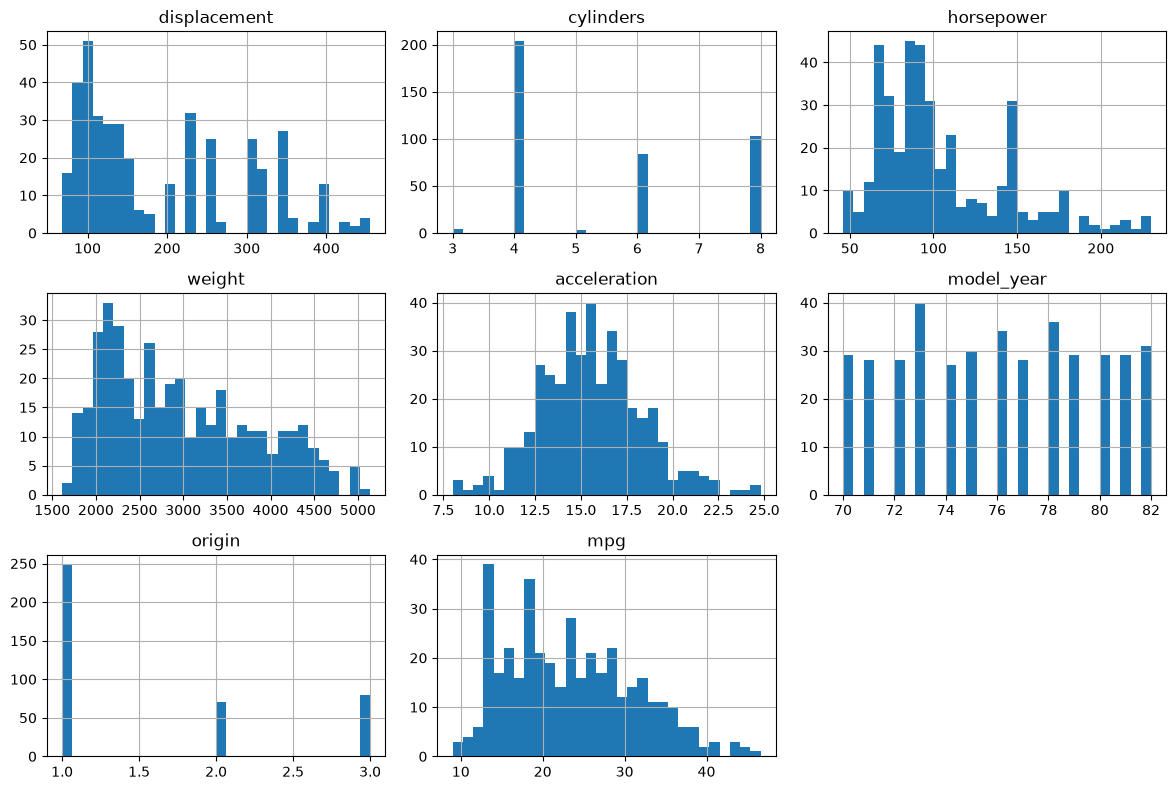

In [6]:
vehicle_data.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [7]:
corr_matrix = vehicle_data.corr(numeric_only=True)

corr_matrix["mpg"].sort_values(ascending=False)

mpg             1.000000
model_year      0.579267
origin          0.563450
acceleration    0.420289
cylinders      -0.775396
horsepower     -0.778427
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64

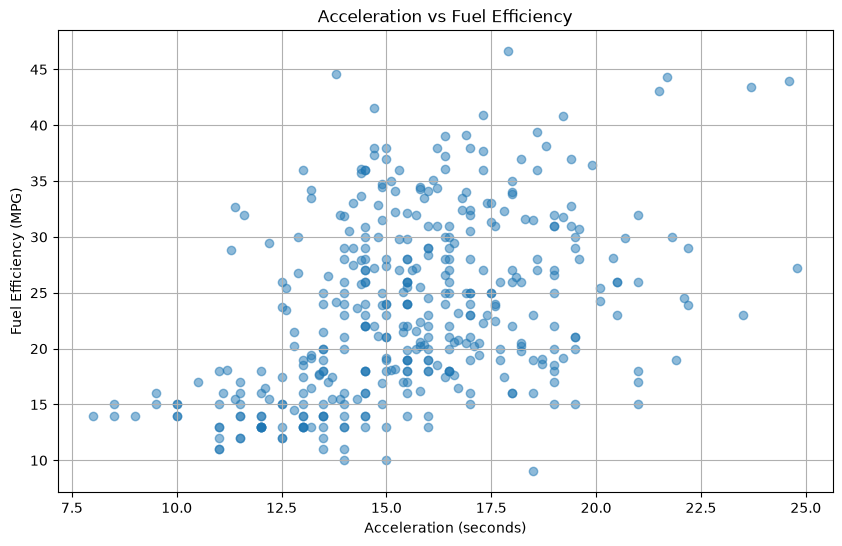

In [8]:
plt.figure(figsize=(10, 6))

plt.scatter(
    vehicle_data["acceleration"],
    vehicle_data["mpg"],
    alpha=0.5
)

plt.xlabel("Acceleration (seconds)")
plt.ylabel("Fuel Efficiency (MPG)")
plt.title("Acceleration vs Fuel Efficiency")
plt.grid(True)
plt.show()

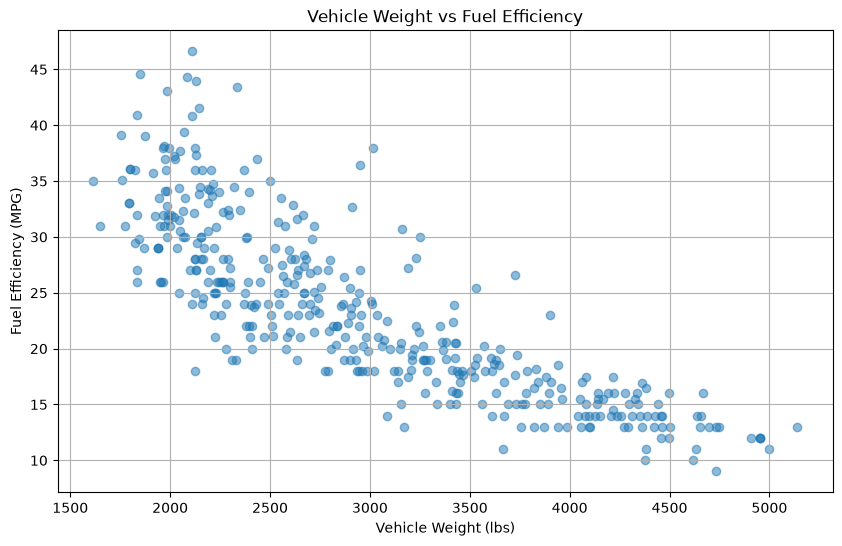

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(
    vehicle_data["weight"],
    vehicle_data["mpg"],
    alpha=0.5
)

plt.xlabel("Vehicle Weight (lbs)")
plt.ylabel("Fuel Efficiency (MPG)")
plt.title("Vehicle Weight vs Fuel Efficiency")
plt.grid(True)
plt.show()

In [10]:
print("Acceleration vs MPG:",
      vehicle_data["acceleration"].corr(vehicle_data["mpg"]))

print("Weight vs MPG:",
      vehicle_data["weight"].corr(vehicle_data["mpg"]))

Acceleration vs MPG: 0.42028891210165065
Weight vs MPG: -0.8317409332443352


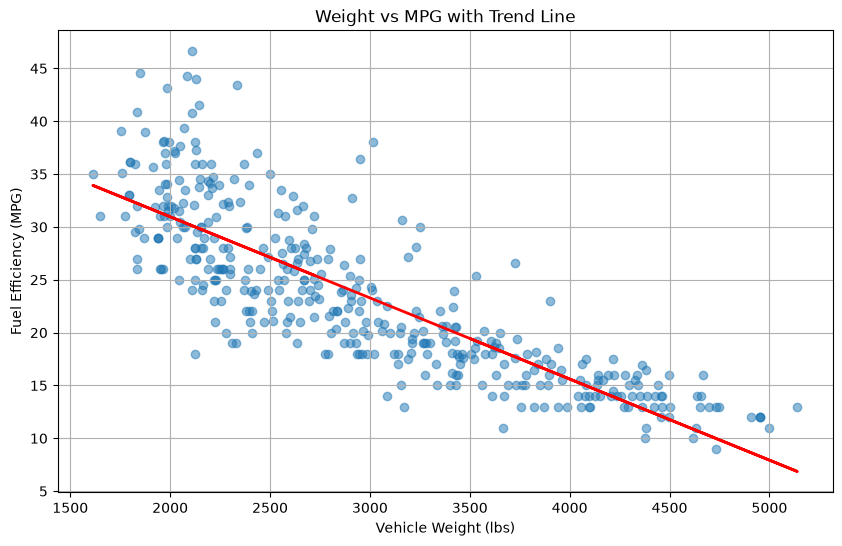

In [11]:
import numpy as np
import matplotlib.pyplot as plt

x = vehicle_data["weight"]
y = vehicle_data["mpg"]

plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.5)

m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color="red", linewidth=2)

plt.xlabel("Vehicle Weight (lbs)")
plt.ylabel("Fuel Efficiency (MPG)")
plt.title("Weight vs MPG with Trend Line")
plt.grid(True)
plt.show()

In [12]:
correlation = vehicle_data["weight"].corr(vehicle_data["mpg"])

print(f"Weight vs MPG correlation: {correlation:.3f}")

Weight vs MPG correlation: -0.832


In [13]:
#The correlation coefficient between vehicle weight and fuel efficiency (MPG) is -0.832, indicating a strong negative linear relationship. This means that heavier vehicles generally have lower fuel efficiency. Therefore, vehicle weight is a promising predictor for the machine learning model.

In [14]:
corr_matrix = vehicle_data.corr(numeric_only=True)

print(corr_matrix["mpg"].sort_values(ascending=False))

mpg             1.000000
model_year      0.579267
origin          0.563450
acceleration    0.420289
cylinders      -0.775396
horsepower     -0.778427
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(
    vehicle_data,
    test_size=0.2,
    random_state=42
)

print("Training set:", train_set.shape)
print("Test set:", test_set.shape)

Training set: (318, 8)
Test set: (80, 8)


In [16]:
# Separate input features and target variable

X_train = train_set.drop("mpg", axis=1)
y_train = train_set["mpg"].copy()

X_test = test_set.drop("mpg", axis=1)
y_test = test_set["mpg"].copy()

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (318, 7)
Training labels: (318,)
Testing features: (80, 7)
Testing labels: (80,)


In [17]:
# Check missing values in training features

X_train.isnull().sum()

displacement    0
cylinders       0
horsepower      5
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [18]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_clean = X_train.copy()

X_train_clean["horsepower"] = imputer.fit_transform(
    X_train[["horsepower"]]
).ravel()

print(X_train_clean.isnull().sum())

displacement    0
cylinders       0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64


In [19]:
X_train_clean.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
3,304.0,8,150.0,3433,12.0,70,1
18,97.0,4,88.0,2130,14.5,70,3
376,91.0,4,68.0,2025,18.2,82,3
248,91.0,4,60.0,1800,16.4,78,3
177,115.0,4,95.0,2694,15.0,75,2


In [20]:
import pandas as pd

X_train_encoded = pd.get_dummies(
    X_train_clean,
    columns=["origin"],
    dtype=int
)

X_train_encoded.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin_1,origin_2,origin_3
3,304.0,8,150.0,3433,12.0,70,1,0,0
18,97.0,4,88.0,2130,14.5,70,0,0,1
376,91.0,4,68.0,2025,18.2,82,0,0,1
248,91.0,4,60.0,1800,16.4,78,0,0,1
177,115.0,4,95.0,2694,15.0,75,0,1,0


In [21]:
from sklearn.preprocessing import StandardScaler

numeric_columns = [
    "displacement",
    "cylinders",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()

X_train_scaled[numeric_columns] = scaler.fit_transform(
    X_train_encoded[numeric_columns]
)

X_train_scaled.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin_1,origin_2,origin_3
3,1.090196,1.527188,1.266232,0.552826,-1.319334,-1.696667,1,0,0
18,-0.922996,-0.850515,-0.407925,-0.999667,-0.413182,-1.696667,0,0,1
376,-0.981350,-0.850515,-0.947975,-1.124772,0.927922,1.638975,0,0,1
248,-0.981350,-0.850515,-1.163996,-1.392854,0.275493,0.527094,0,0,1
177,-0.747936,-0.850515,-0.218907,-0.327675,-0.231952,-0.306816,0,1,0


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical features
numeric_features = [
    "displacement",
    "cylinders",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

# Categorical features
categorical_features = ["origin"]

# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Complete preprocessing pipeline
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Fit and transform training data
X_train_prepared = full_pipeline.fit_transform(X_train)

print("Prepared training data shape:", X_train_prepared.shape)

Prepared training data shape: (318, 9)


In [23]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
lin_reg = LinearRegression()

# Train the model
lin_reg.fit(X_train_prepared, y_train)

# Predict MPG for training data
mpg_predictions = lin_reg.predict(X_train_prepared)

# Compare actual MPG with predicted MPG
comparison = pd.DataFrame({
    "Actual MPG": y_train.values,
    "Predicted MPG": mpg_predictions
})

comparison.head(10)

,Actual MPG,Predicted MPG
0,16.0,15.083849
1,27.0,24.581260
2,37.0,35.654748
3,36.1,33.933098
4,23.0,25.298667
5,14.0,11.562340
6,32.8,32.692141
7,29.9,30.005748
8,20.0,26.311886
9,12.0,8.596259


In [24]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Calculate Mean Squared Error
lin_mse = mean_squared_error(y_train, mpg_predictions)

# Calculate Root Mean Squared Error
lin_rmse = np.sqrt(lin_mse)

print(f"Linear Regression RMSE: {lin_rmse:.2f} MPG")

Linear Regression RMSE: 3.37 MPG


In [25]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
import numpy as np

# Combine preprocessing and Linear Regression
lin_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", LinearRegression())
])

# Perform 5-fold cross-validation
lin_scores = cross_val_score(
    lin_pipeline,
    X_train,
    y_train,
    scoring="neg_mean_squared_error",
    cv=5
)

# Convert MSE scores into RMSE
lin_rmse_scores = np.sqrt(-lin_scores)

print("Cross-validation RMSE:", lin_rmse_scores)
print(f"Mean RMSE: {lin_rmse_scores.mean():.2f} MPG")
print(f"Standard Deviation: {lin_rmse_scores.std():.2f}")

Cross-validation RMSE: [3.21817071 3.23259376 3.60651994 3.68270794 3.56040751]
Mean RMSE: 3.46 MPG
Standard Deviation: 0.20


In [26]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import numpy as np

# Create Decision Tree pipeline
tree_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Train the model
tree_pipeline.fit(X_train, y_train)

# Predict MPG on training data
tree_predictions = tree_pipeline.predict(X_train)

# Calculate training RMSE
tree_rmse = np.sqrt(
    mean_squared_error(y_train, tree_predictions)
)

print(f"Decision Tree Training RMSE: {tree_rmse:.2f} MPG")

Decision Tree Training RMSE: 0.00 MPG


In [27]:
from sklearn.model_selection import cross_val_score
import numpy as np

# Perform 5-fold cross-validation
tree_scores = cross_val_score(
    tree_pipeline,
    X_train,
    y_train,
    scoring="neg_mean_squared_error",
    cv=5
)

# Calculate RMSE
tree_rmse_scores = np.sqrt(-tree_scores)

print("Decision Tree CV RMSE:", tree_rmse_scores)
print(f"Mean RMSE: {tree_rmse_scores.mean():.2f} MPG")
print(f"Standard Deviation: {tree_rmse_scores.std():.2f}")

Decision Tree CV RMSE: [3.99808548 3.36340601 3.8778417  4.13784316 3.72375472]
Mean RMSE: 3.82 MPG
Standard Deviation: 0.27


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
import numpy as np

# Create Random Forest pipeline
forest_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Random Forest
forest_pipeline.fit(X_train, y_train)

# Predict training MPG
forest_predictions = forest_pipeline.predict(X_train)

# Calculate training RMSE
forest_rmse = np.sqrt(
    mean_squared_error(y_train, forest_predictions)
)

print(f"Random Forest Training RMSE: {forest_rmse:.2f} MPG")

Random Forest Training RMSE: 1.09 MPG


In [29]:
# Perform 5-fold cross-validation
forest_scores = cross_val_score(
    forest_pipeline,
    X_train,
    y_train,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

# Calculate RMSE
forest_rmse_scores = np.sqrt(-forest_scores)

print("Random Forest CV RMSE:", forest_rmse_scores)
print(f"Mean RMSE: {forest_rmse_scores.mean():.2f} MPG")
print(f"Standard Deviation: {forest_rmse_scores.std():.2f}")

Random Forest CV RMSE: [2.9013851  2.80500009 3.36566735 3.82603443 2.71388544]
Mean RMSE: 3.12 MPG
Standard Deviation: 0.42


In [30]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter combinations
param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__max_features": [3, 5, 7],
    "model__max_depth": [5, 10, None]
}

# Grid Search
grid_search = GridSearchCV(
    forest_pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Find best parameters
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print(
    f"Best Cross-Validation RMSE: "
    f"{np.sqrt(-grid_search.best_score_):.2f} MPG"
)

Best Parameters:
{'model__max_depth': 10, 'model__max_features': 3, 'model__n_estimators': 50}
Best Cross-Validation RMSE: 3.02 MPG


In [31]:
import pandas as pd

# Get the best tuned model
best_model = grid_search.best_estimator_

# Extract feature names
feature_names = best_model.named_steps[
    "preprocessing"
].get_feature_names_out()

# Extract feature importance scores
feature_importances = best_model.named_steps[
    "model"
].feature_importances_

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
}).sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

             Feature  Importance
1     num__cylinders    0.271750
0  num__displacement    0.234190
3        num__weight    0.177141
2    num__horsepower    0.142134
5    num__model_year    0.105203
4  num__acceleration    0.038448
6      cat__origin_1    0.021442
8      cat__origin_3    0.005146
7      cat__origin_2    0.004547


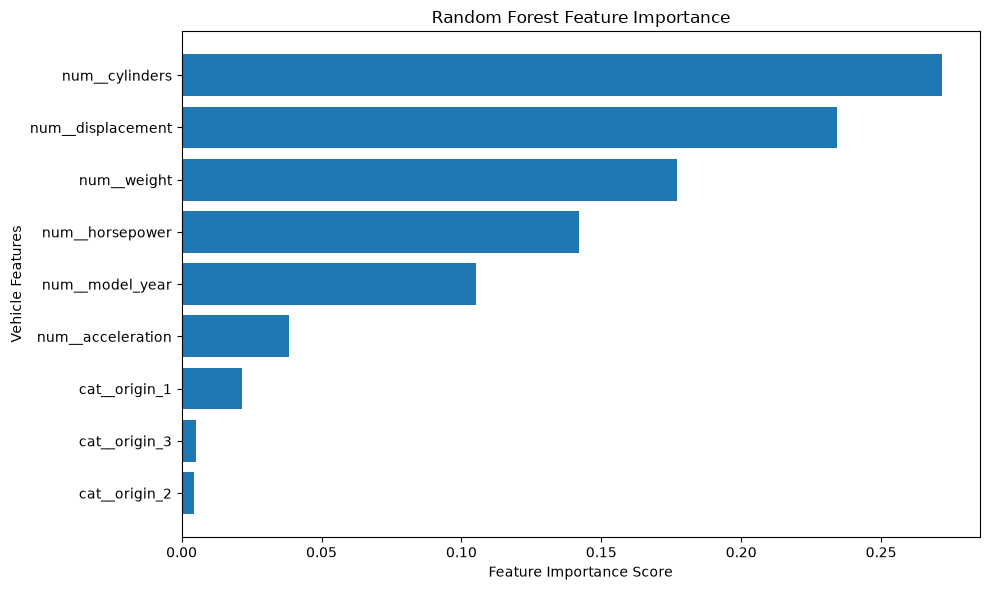

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Vehicle Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [33]:
from sklearn.model_selection import cross_val_predict
import pandas as pd

# Cross-validated predictions using tuned model
cv_predictions = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=5,
    n_jobs=-1
)

# Compare actual and predicted MPG
error_analysis = pd.DataFrame({
    "Actual MPG": y_train.values,
    "Predicted MPG": cv_predictions
})

# Calculate prediction errors
error_analysis["Error"] = (
    error_analysis["Actual MPG"] -
    error_analysis["Predicted MPG"]
)

error_analysis["Absolute Error"] = (
    error_analysis["Error"].abs()
)

# Display vehicles with largest errors
error_analysis.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

,Actual MPG,Predicted MPG,Error,Absolute Error
198,38.0,20.609167,17.390833,17.390833
164,44.6,33.864267,10.735733,10.735733
232,26.6,16.547810,10.052190,10.052190
132,32.7,23.450667,9.249333,9.249333
169,43.1,34.310833,8.789167,8.789167
252,41.5,33.124696,8.375304,8.375304
233,46.6,38.716900,7.883100,7.883100
119,36.4,28.660667,7.739333,7.739333
67,18.0,25.719000,-7.719000,7.719000
11,23.7,31.377600,-7.677600,7.677600


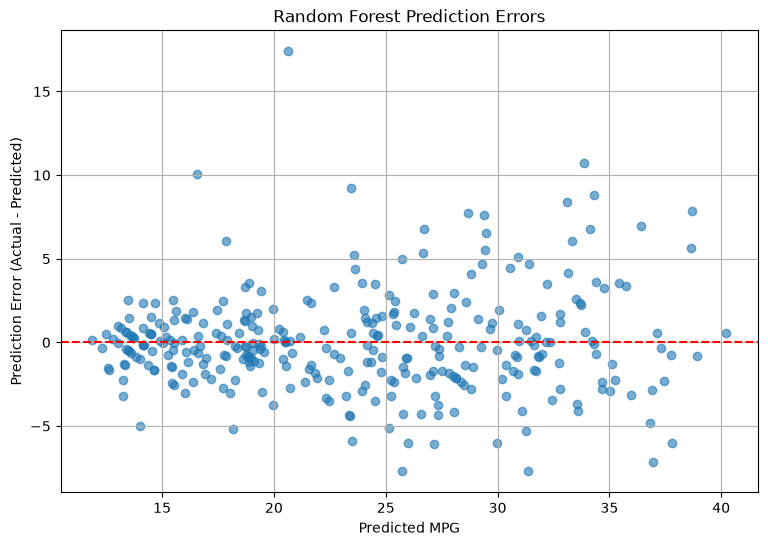

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    error_analysis["Predicted MPG"],
    error_analysis["Error"],
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted MPG")
plt.ylabel("Prediction Error (Actual - Predicted)")
plt.title("Random Forest Prediction Errors")
plt.grid(True)
plt.show()

In [35]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Use the best model from GridSearchCV
final_model = grid_search.best_estimator_

# Predict MPG on unseen test data
final_predictions = final_model.predict(X_test)

# Calculate evaluation metrics
final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

final_mae = mean_absolute_error(
    y_test, final_predictions
)

final_r2 = r2_score(
    y_test, final_predictions
)

print(f"Final Test RMSE: {final_rmse:.2f} MPG")
print(f"Final Test MAE: {final_mae:.2f} MPG")
print(f"Final Test R² Score: {final_r2:.3f}")

Final Test RMSE: 2.20 MPG
Final Test MAE: 1.64 MPG
Final Test R² Score: 0.910


In [36]:
import joblib

# Save the complete trained model
joblib.dump(final_model, "vehicle_mpg_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [37]:
loaded_model = joblib.load("vehicle_mpg_model.pkl")